<a href="https://colab.research.google.com/github/christinafan-cell/MSSP607/blob/main/Assignments/case%20study/case%20study3/Assignment3_Christina_Fan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Case Study Report Assignment 3
## Housing Prices and Purchase Recommendations for ABC


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
# Load the assigned dataset directly from the GitHub data folder.
url = 'https://raw.githubusercontent.com/christinafan-cell/MSSP607/main/data/HousingPrices.csv'
df = pd.read_csv(url)
print('Original shape:', df.shape)
display(df.head())


Original shape: (1460, 17)


,Id,LotFrontage,LotArea,HouseStyle,OverallQual,OverallCond,YearBuilt,TotalBsmtSF,CentralAir,1stFlrSF,2ndFlrSF,FullBath,TotalRooms,GarageCars,GarageArea,YrSold,SalePrice
0,1,65.0,8450.0,2Story,7,5,2003,856.0,Y,856,854,2,8,2,548,2008,208500
1,2,80.0,9600.0,1Story,6,8,1976,NaN,Y,1262,0,2,6,2,460,2007,181500
2,3,68.0,11250.0,2Story,7,5,2001,920.0,Y,920,866,2,6,2,608,2008,223500
3,4,60.0,9550.0,2Story,7,5,1915,NaN,Y,961,756,1,7,3,642,2006,140000
4,5,84.0,14260.0,2Story,8,5,2000,1145.0,Y,1145,1053,2,9,3,836,2008,250000


## 1 Data quality
Check missing values and duplicates. Missing characteristics remain unknown rather than being changed to zero. All valid sale prices are retained.

In [2]:
df.columns = df.columns.str.strip()
display(df.isna().sum().rename('Missing values').to_frame())
print('Duplicate rows:', df.duplicated().sum())
print('Duplicate IDs:', df['Id'].duplicated().sum())
df['SalePrice'] = pd.to_numeric(df['SalePrice'], errors='coerce')
assert df['SalePrice'].notna().all() and (df['SalePrice'] > 0).all()
assert not df['Id'].duplicated().any()
price = df['SalePrice']
print('Sale years:', df['YrSold'].min(), 'to', df['YrSold'].max())


,Missing values
Id,0
LotFrontage,259
LotArea,119
HouseStyle,0
OverallQual,0
OverallCond,0
YearBuilt,0
TotalBsmtSF,547
CentralAir,0
1stFlrSF,0


Duplicate rows: 0
Duplicate IDs: 0
Sale years: 2006 to 2010


## 2 Mean and standard deviation
Sample standard deviation uses ddof=1. Quartiles and median provide robust context. Monetary amounts are interpreted as US dollars, following the original dataset.

In [3]:
summary = price.describe().rename('Sale price')
display(summary.to_frame().round(2))
print('Mean: $' + format(price.mean(), ',.2f'))
print('Sample SD: $' + format(price.std(ddof=1), ',.2f'))
print('Median: $' + format(price.median(), ',.2f'))


,Sale price
count,1460.0
mean,180921.2
std,79442.5
min,34900.0
25%,129975.0
50%,163000.0
75%,214000.0
max,755000.0


Mean: $180,921.20
Sample SD: $79,442.50
Median: $163,000.00


## 3 Histogram
All prices are plotted. A long right tail and mean above median indicate right skew.

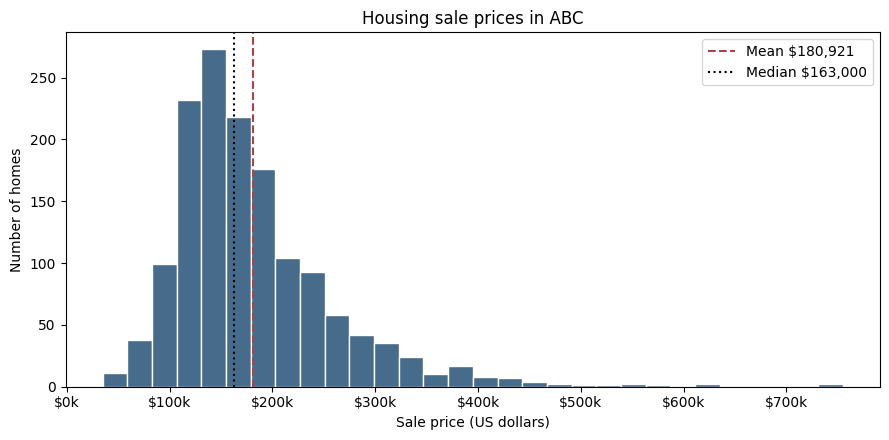

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(price, bins=30, color='#476B8A', edgecolor='white')
ax.axvline(price.mean(), linestyle='--', color='#AA4444', label='Mean $' + format(price.mean(), ',.0f'))
ax.axvline(price.median(), linestyle=':', color='black', label='Median $' + format(price.median(), ',.0f'))
ax.set(title='Housing sale prices in ABC', xlabel='Sale price (US dollars)', ylabel='Number of homes')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, pos: '$' + format(v/1000, ',.0f') + 'k'))
ax.legend()
fig.tight_layout()
fig.savefig('housing_histogram.png', dpi=180, bbox_inches='tight')
plt.show()


## 4 Outliers and sensitivity
Use the 1.5 × IQR rule. Flags identify records for review, not proven errors. Keep all sales for the primary results; exclusion below is only a sensitivity check.

IQR: 84025.0 | Lower fence: 3937.5 | Upper fence: 340037.5
Flagged: 61 (4.18%)
Low flags: 0 | High flags: 61


,Id,SalePrice,OverallQual,YearBuilt,GarageCars
691,692,755000,10,1994,3
1182,1183,745000,10,1996,3
1169,1170,625000,10,1995,3
898,899,611657,9,2009,3
803,804,582933,9,2008,3
...,...,...,...,...,...
990,991,348000,8,1997,3
642,643,345000,8,1972,2
11,12,345000,9,2005,3
320,321,342643,9,2006,3


,All sales,Without IQR flags
N,1460.0,1399.00
Mean,180921.2,170237.13
Median,163000.0,159500.00
Sample SD,79442.5,59230.13


Mean reduction: 5.91%


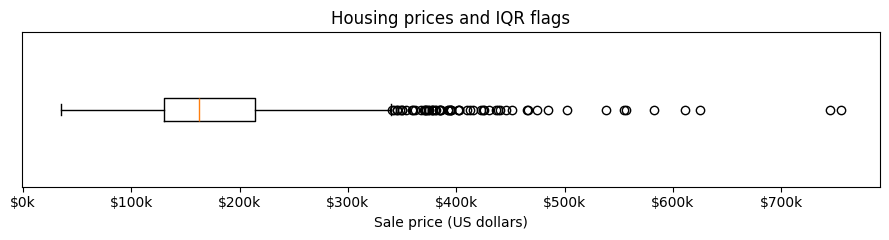

In [5]:
q1, q3 = price.quantile([0.25, 0.75])
iqr = q3 - q1
lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
flag = (price < lower) | (price > upper)
unflagged = price[~flag]
print('IQR:', iqr, '| Lower fence:', lower, '| Upper fence:', upper)
print(f'Flagged: {flag.sum()} ({flag.mean():.2%})')
print('Low flags:', (price < lower).sum(), '| High flags:', (price > upper).sum())
display(df.loc[flag, ['Id','SalePrice','OverallQual','YearBuilt','GarageCars']].sort_values('SalePrice', ascending=False))
sensitivity = pd.DataFrame({
    'All sales': [len(price), price.mean(), price.median(), price.std(ddof=1)],
    'Without IQR flags': [len(unflagged), unflagged.mean(), unflagged.median(), unflagged.std(ddof=1)]
}, index=['N','Mean','Median','Sample SD'])
display(sensitivity.round(2))
print(f'Mean reduction: {1-unflagged.mean()/price.mean():.2%}')
fig, ax = plt.subplots(figsize=(9, 2.5))
ax.boxplot(price, vert=False)
ax.set(title='Housing prices and IQR flags', xlabel='Sale price (US dollars)', yticks=[])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, pos: '$' + format(v/1000, ',.0f') + 'k'))
fig.tight_layout()
fig.savefig('housing_boxplot.png', dpi=180, bbox_inches='tight')
plt.show()


## 5 Additional patterns
Property quality, size, age, and garage capacity help select comparable sales. Correlations use complete pairs and do not estimate causal effects or adjusted premiums.

In [6]:
# This is the sum of two floor-area fields, not all finished living area.
df['TwoFloorSF'] = df['1stFlrSF'] + df['2ndFlrSF']
features = ['OverallQual','TwoFloorSF','GarageCars','GarageArea','YearBuilt','LotArea','TotalBsmtSF']
correlations = pd.DataFrame({
    'Pearson r': [df[[f,'SalePrice']].corr().iloc[0,1] for f in features],
    'Complete pairs': [df[[f,'SalePrice']].dropna().shape[0] for f in features]
}, index=features).sort_values('Pearson r', ascending=False)
display(correlations.round(3))
quality = df.groupby('OverallQual')['SalePrice'].agg(N='count', Median='median', Mean='mean')
display(quality.round(2))
display(df['YrSold'].value_counts().sort_index().rename('Homes').to_frame())


,Pearson r,Complete pairs
OverallQual,0.791,1460
TwoFloorSF,0.717,1460
TotalBsmtSF,0.642,913
GarageCars,0.640,1460
GarageArea,0.623,1460
YearBuilt,0.523,1460
LotArea,0.268,1341


,N,Median,Mean
OverallQual,,,
1,2,50150.0,50150.00
2,3,60000.0,51770.33
3,20,86250.0,87473.75
4,116,108000.0,108420.66
5,397,133000.0,133523.35
6,374,160000.0,161603.03
7,319,200141.0,207716.42
8,168,269750.0,274735.54
9,43,345000.0,367513.02


,Homes
YrSold,
2006,314
2007,329
2008,304
2009,338
2010,175


## 6 Conclusions and recommendations
Mean price is **$180,921.20** and sample SD is **$79,442.50**. Median is **$163,000**; the middle half ranges from **$129,975 to $214,000**. All **61 IQR flags (4.18%)** exceed **$340,037.50**. Exclusion lowers mean to **$170,237.13** and SD to **$59,230.13**; this does not replace the full-sample estimates.

Use median-based historical orientation and compare similar quality, area, age, garage capacity, and sale dates. Quality levels 5, 6, and 7 have medians of $133,000, $160,000, and $200,141. These are unadjusted group comparisons. Obtain an inspection, repair estimates, current comparable sales, and total ownership costs before making an offer. A low price alone does not establish a bargain. The sales occurred in 2006–2010 and cannot establish current values or future appreciation.

In [7]:
# Verify the assigned dataset and key report numbers.
assert len(df) == 1460 and price.count() == 1460
assert int(flag.sum()) == 61
assert int(flag.sum() + (~flag).sum()) == len(df)
assert np.isclose(price.mean(), 180921.19589041095)
assert np.isclose(price.std(ddof=1), 79442.50288288662)
assert np.isclose(unflagged.mean(), 170237.1272337384)
assert quality['N'].sum() == len(df)
print('All verification checks passed.')
print('pandas:', pd.__version__, '| NumPy:', np.__version__)


All verification checks passed.
pandas: 2.2.3 | NumPy: 2.4.6
